In [1]:
import pandas as pd

In [4]:
df = df = pd.read_csv('automobileEDA.csv')
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [5]:
x = df.drop("price", axis=1)  
y = df['price']

In [6]:
from sklearn.model_selection import train_test_split

In [7]:

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [8]:
to_select = ['horsepower','curb-weight','engine-size','highway-mpg']
x_train = X_train[to_select].values
x_test = X_test[to_select].values


In [9]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()


In [10]:
model.fit(x_train, y_train)

LinearRegression()

In [11]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)


In [12]:
model.intercept_

-8009.241208155732

In [13]:
model.coef_

array([ 25.9407567 ,   3.7778736 ,  83.14757024, -65.72539722])

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

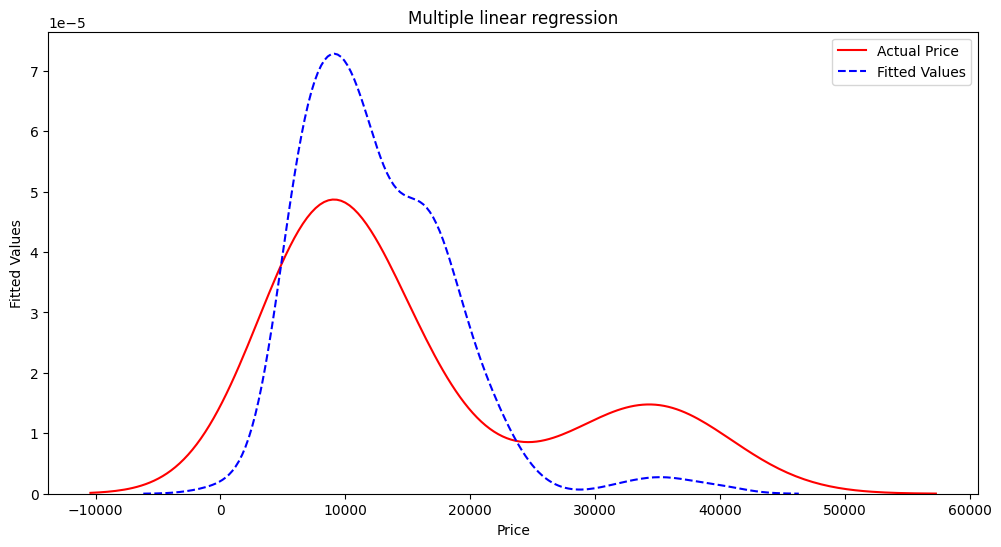

In [15]:
plt.figure(figsize=(12, 6))
ax1 = sns.kdeplot(y_test, color='r', label='Actual Price')
sns.kdeplot(y_pred_train, color='b', label='Fitted Values', ax=ax1, linestyle='--') #Color is not changed so linestyle is changed
plt.title("Multiple linear regression")
plt.xlabel("Price")
plt.ylabel("Fitted Values")
plt.legend()  
plt.show()
plt.close()

## Mean Square Error (MSE)

The Mean Square Error (MSE) is a common loss function used in regression problems to measure the average of the squares of the errors—that is, the average squared difference between the estimated values and the actual value. The MSE is always non-negative, and values closer to zero are better. The formula for calculating MSE is given by:

$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

Where:
- $n$ is the number of observations,
- $y_i$ is the actual value of the i-th observation,
- $\hat{y}_i$ is the predicted value for the i-th observation.


In [16]:
x= df['horsepower'].values.reshape(-1, 1)
y = df['price'].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [17]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)


In [18]:
from sklearn.metrics import mean_squared_error

In [19]:
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

print(f"Train Mean Squared Error: {mse_train}")
print(f"Test Mean Squared Error: {mse_test}")

print('\n')
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Train Mean Squared Error: 16320010.468020136
Test Mean Squared Error: 46093655.049259596


Coefficients: [[151.88933994]]
Intercept: [-2907.17676069]


## MSE using numpy

In [20]:
import numpy as np

In [21]:
mse=np.mean((y_train - y_pred_train) ** 2)
mse

16320010.468020136

## MSE using sklearn

In [22]:
from sklearn.metrics import mean_squared_error

In [23]:
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
mse_train, mse_test

(16320010.468020136, 46093655.049259596)

## Visualization

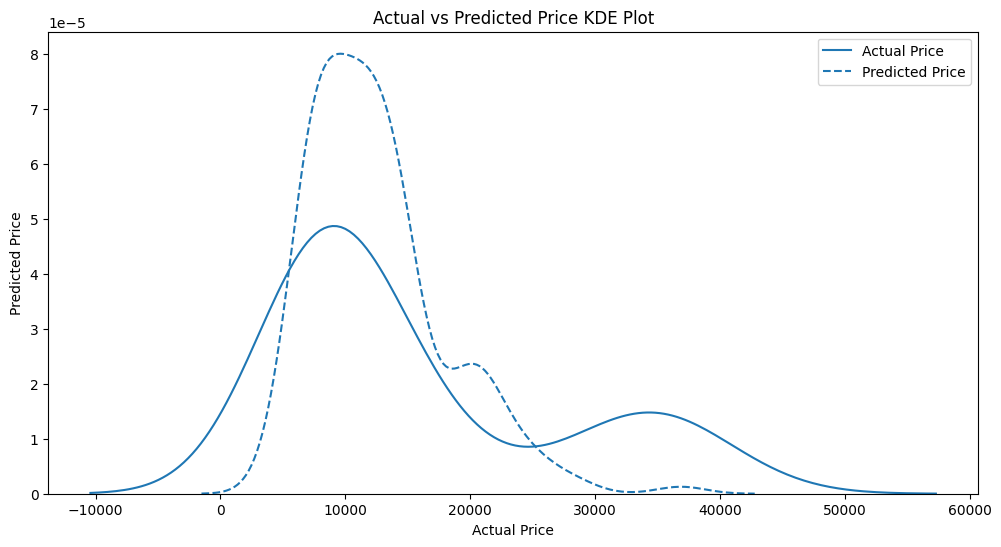

In [24]:
plt.figure(figsize=(12,6))
ax1 = sns.kdeplot(y_test,  label='Actual Price')
sns.kdeplot(y_pred_train,  label= 'Predicted Price',  ax=ax1, linestyle='--')#Color is not changed so linestyle is changed
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price KDE Plot')
plt.legend()
plt.show()

## Mean Absolute Error (MAE)

The Mean Absolute Error (MAE) is a metric used to measure the average magnitude of the errors between pairs of predictions and actual outcomes, without considering their direction. It's the mean over the test sample of the absolute differences between predicted and actual values. MAE provides a straightforward indication of average error magnitude in the same units as the data. The MAE formula is:

$$
\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$

Where:
- $n$ is the number of observations,
- $y_i$ is the actual value for the i-th observation,
- $\hat{y}_i$ is the predicted value for the i-th observation.

MAE is particularly useful for understanding the average error magnitude directly in the output variable's units.



In [25]:
from sklearn.metrics import mean_absolute_error 

In [26]:
mse_train = mean_absolute_error(y_train, y_pred_train)
mse_test = mean_absolute_error(y_test, y_pred_test)
mse_train, mse_test

(2877.7586831038134, 4809.393573026446)

## Root Mean Square Error (RMSE)

The Root Mean Square Error (RMSE) is another metric used to measure the average magnitude of the error. It's the square root of the average of squared differences between the predicted values and actual values. Compared to MAE, RMSE gives a relatively high weight to large errors. This means RMSE is more sensitive to outliers than MAE. The RMSE formula is:

$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}
$$

Where:
- $n$ is the number of observations,
- $y_i$ is the actual value of the i-th observation,
- $\hat{y}_i$ is the predicted value for the i-th observation.

RMSE is valuable when large errors are particularly undesirable and should be penalized more than smaller errors. It is also more appropriate than MAE when the error distribution is expected to be Gaussian.


In [29]:
pip install root_mean_squared_error

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement root_mean_squared_error (from versions: none)
ERROR: No matching distribution found for root_mean_squared_error

[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
pip install sklearn.metrics

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sklearn.metrics (from versions: none)
ERROR: No matching distribution found for sklearn.metrics

[notice] A new release of pip is available: 23.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from sklearn.metrics import root_mean_squared_error
mse_train = root_mean_squared_error(y_train, y_pred_train)
mse_test = root_mean_squared_error(y_test, y_pred_test)
mse_train, mse_test

ImportError: cannot import name 'root_mean_squared_error' from 'sklearn.metrics' (C:\Users\arun\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\__init__.py)